## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Set the path to your dataset in Google Drive (edit the folder name below)
DATA_PATH = "/content/processed.cleveland.csv"


## Cell 2 — Import Libraries

In [ ]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)


## Cell 3 — Load Dataset

In [ ]:
# TODO: Load the UCI Heart Disease dataset from DATA_PATH
# The raw UCI file has no header row and uses '?' for missing values -- handle both.
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

df = pd.read_csv(DATA_PATH, header=None, names=columns, na_values='?')



## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?

In [ ]:
# TODO: Inspect shape, columns, dtypes, head(), and describe()
# 1 samples and features
print(f"Shape of dataset: {df.shape[0]} samples, {df.shape[1]} total columns (13 features + 1 target)\n")

# 2 column names and data types
print("Column Names and Data Types:")
print(df.dtypes)
print("\n")

# 3 first 5 rows
print("First 5 Rows:")
display(df.head())

# 4 descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe())

# 5 target variable and values
print("\nTarget Variable Value Counts:")
print(df['target'].value_counts())

Shape of dataset: 303 samples, 14 total columns (13 features + 1 target)

Column Names and Data Types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object


First 5 Rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Descriptive Statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000



Target Variable Value Counts:
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


Shape & Types: We're working with 303 patient records across 14 columns (13 predictor features and 1 target). Most of the data types are standard integers and floats. Since we swapped the missing '?' characters to NaNs, the ca and thal columns automatically loaded as floats.   The Data (head & describe): A quick look at the first few rows and the summary stats shows that our features are on completely different scales. For instance, patient ages range from 29 to 77 and cholesterol levels go over 500, while oldpeak values are mostly under 6. This is a clear sign we'll need to scale our data before feeding it to the neural network.The Target: The variable we are predicting is simply called target. In this raw dataset, it actually takes five values: 0 means no heart disease, and 1 through 4 represent varying levels of the disease. Since our goal is binary classification, we'll eventually just treat 0 as "negative" and everything else as "positive"

## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

Count of each class:
target
0    164
1    139
Name: count, dtype: int64

Percentage of each class:
target
0    54.125413
1    45.874587
Name: proportion, dtype: float64


/tmp/ipykernel_791/4239104912.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='target', palette='Set2')


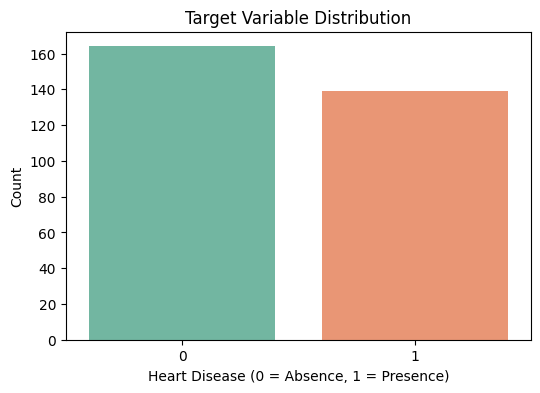

In [ ]:
# TODO: Count target classes, compute percentages, and plot the distribution
df['target'] = (df['target'] > 0).astype(int)

# 1. Count of each class
class_counts = df['target'].value_counts()
print("Count of each class:")
print(class_counts)

# 2. Percentage of each class
class_percentages = df['target'].value_counts(normalize=True) * 100
print("\nPercentage of each class:")
print(class_percentages)

# 3. Plot the target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='target', palette='Set2')
plt.title('Target Variable Distribution')
plt.xlabel('Heart Disease (0 = Absence, 1 = Presence)')
plt.ylabel('Count')
plt.show()

The dataset is balanced. After converting the target to a binary format , the distribution sits at roughly 54% for class 0 (absence) and 46% for class 1 (presence). Because neither class overwhelmingly dominates the other, the model will have enough examples to effectively learn the patterns for both outcomes without requiring special techniques like oversampling.

## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

In [ ]:
# TODO: Check for missing values, duplicates, dtypes, and unique values per column
# 1. Check for missing values
print("Missing Values per Column:")
print(df.isnull().sum())

# 2. Check for duplicate rows
duplicate_count = df.duplicated().sum()
print(f"\nNumber of Duplicate Rows: {duplicate_count}")

# 3. Data types of each column
print("\nData Types:")
print(df.dtypes)

# 4. Unique values per column
print("\nUnique Values per Column:")
print(df.nunique())

Missing Values per Column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Number of Duplicate Rows: 0

Data Types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Unique Values per Column:
age          41
sex           2
cp            4
trestbps     50
chol        152
fbs           2
restecg       3
thalach      91
exang         2
oldpeak      40
slope         3
ca            4
thal          3
target        2
dtype: int64


## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

/tmp/ipykernel_791/1395288720.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='target', palette='Set2')


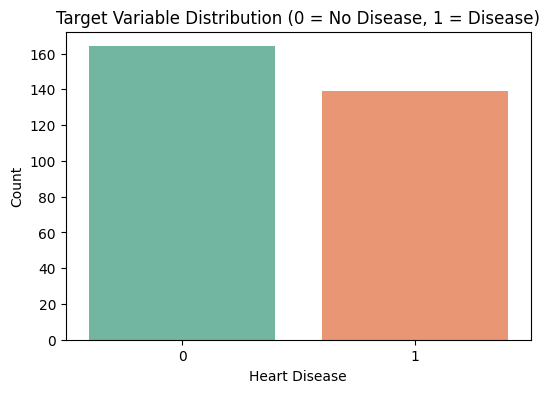

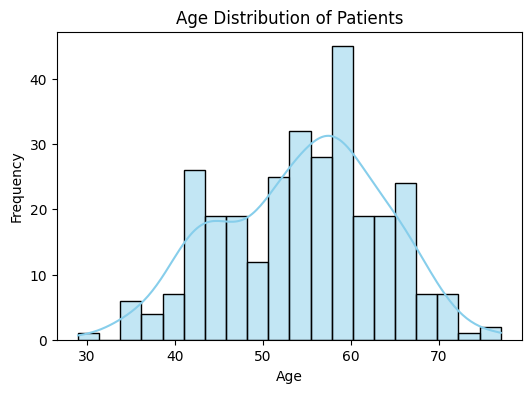

/tmp/ipykernel_791/1395288720.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target', y='thalach', palette='Set1')


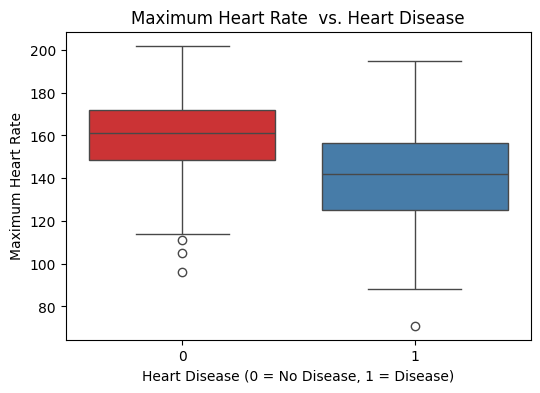

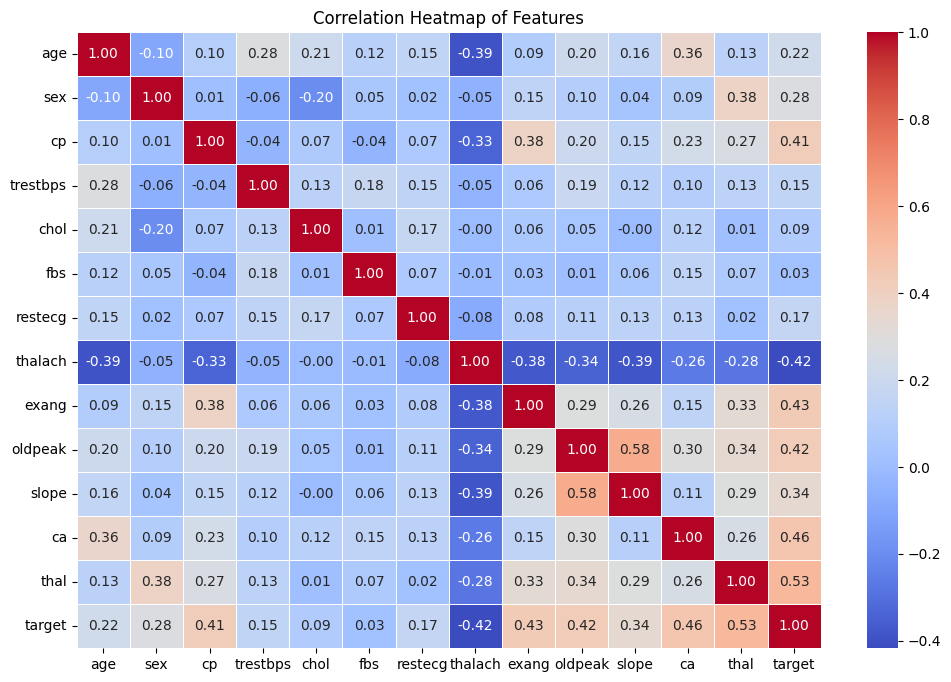

In [ ]:
# TODO: Create the required visualizations
#  Target distribution plot
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='target', palette='Set2')
plt.title('Target Variable Distribution (0 = No Disease, 1 = Disease)')
plt.xlabel('Heart Disease')
plt.ylabel('Count')
plt.show()

#  Age distribution
plt.figure(figsize=(6, 4))
sns.histplot(df['age'], bins=20, kde=True, color='skyblue')
plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

#  Maximum Heart Rate vs. Target
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='target', y='thalach', palette='Set1')
plt.title('Maximum Heart Rate  vs. Heart Disease')
plt.xlabel('Heart Disease (0 = No Disease, 1 = Disease)')
plt.ylabel('Maximum Heart Rate')
plt.show()

#  Correlation heatmap of numerical features
plt.figure(figsize=(12, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Features')
plt.show()

## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. Define X and y
X = df.drop(columns=["target"])
y = df["target"]

# 2. Split into train/test sets FIRST to prevent data leakage (70/30 split)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. Identify numerical and categorical features
numerical_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

# 4. Build preprocessing pipelines
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')), # Fills missing 'ca' values
    ('scaler', StandardScaler())                   # Scales all numericals
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')), # Fills missing 'thal' values
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) # One-hot encodes categories
])

# Combine them into a ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', num_pipeline, numerical_features),
    ('cat', cat_pipeline, categorical_features)
])

# 5. Fit on TRAIN, Transform on TRAIN and TEST
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 6. Convert the processed numpy arrays to PyTorch tensors
X_train = torch.tensor(X_train_processed, dtype=torch.float32)
X_test = torch.tensor(X_test_processed, dtype=torch.float32)

y_train = torch.tensor(y_train.values, dtype=torch.long)
y_test = torch.tensor(y_test.values, dtype=torch.long)

print(f"Processed X_train shape: {X_train.shape}")
print(f"Processed X_test shape: {X_test.shape}")

Processed X_train shape: torch.Size([212, 25])
Processed X_test shape: torch.Size([91, 25])


In [ ]:
# Create TensorDatasets
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)


## Cell 9 — Design Your Own Neural Network

Design a neural network with **4-5 layers total** (input + hidden layers + output). Decide the number of neurons, hidden layers, and activation functions.

Fill in the table with your design:

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    |         |            |
| Hidden 1 |         |            |
| Hidden 2 |         |            |
| Hidden 3 |         |            |
| Hidden 4 |         |            |
| Output   |         |            |

*(Delete rows you don't use if your design has fewer than 4 hidden layers.)*

In [ ]:
import torch.nn as nn

# Define the Artificial Neural Network architecture
class HeartDiseaseNN(nn.Module):
    def __init__(self):
        super(HeartDiseaseNN, self).__init__()

        # Layer 1: Input (25 features) -> Hidden 1 (16 neurons)
        self.hidden1 = nn.Linear(in_features=25, out_features=16)

        # Layer 2: Hidden 1 (16 neurons) -> Hidden 2 (8 neurons)
        self.hidden2 = nn.Linear(in_features=16, out_features=8)

        # Layer 3: Hidden 2 (8 neurons) -> Output (1 neuron)
        self.output = nn.Linear(in_features=8, out_features=1)

        # Activation Functions
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # Pass data through Hidden 1 + ReLU
        x = self.relu(self.hidden1(x))
        # Pass data through Hidden 2 + ReLU
        x = self.relu(self.hidden2(x))
        # Pass data through Output + Sigmoid
        x = self.sigmoid(self.output(x))
        return x

# Create an instance of the model to verify it
model = HeartDiseaseNN()
print(model)

HeartDiseaseNN(
  (hidden1): Linear(in_features=25, out_features=16, bias=True)
  (hidden2): Linear(in_features=16, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=1, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
)


## Cell 10 — Manually Calculate Parameters

For **each layer** in your design above, manually calculate the number of trainable parameters using:

`Parameters = (Input units × Output units) + Output units`

Complete the table:

| Layer    | Input Units | Output Units | Calculation | Parameters |
|----------|------------:|-------------:|-------------|-----------:|
| Hidden 1 |     25      |   16          |(25*16)+16   | 416        |
| Hidden 2 |     16        | 8           |(16*8)+8     |136            |
| Hidden 3 |           |            |      |            |
| Hidden 4 |             |               |             |            |
| Output   |      8       | 1            | (8*1)+1     | 9           |
| **Total**|             |               |             | 561
           |

Later, compare this total to what `model.summary()` reports in Cell 11.

## Cell 11 — Implement Neural Network in PyTorch


In [ ]:
# TODO: Implement the architecture you designed in Cell 9
import torch
import torch.nn as nn

class MyModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()

        self.model = nn.Sequential(
            # Input → Hidden 1 (25 features in, 16 neurons out)
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),

            # Hidden 1 → Hidden 2 (16 neurons in, 8 neurons out)
            nn.Linear(hidden_dim, 8),
            nn.ReLU(),

            # Hidden 2 → Output layer (8 neurons in, 1 probability score out)
            nn.Linear(8, output_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

# Create model with our exact custom dimensions
model = MyModel(
    input_dim=25,
    hidden_dim=16,
    output_dim=1
)

print(model)

MyModel(
  (model): Sequential(
    (0): Linear(in_features=25, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

In [ ]:
# TODO: Choose an appropriate loss function
loss_function = nn.BCELoss()


Binary Cross-Entropy (BCELoss) is the standard loss function for binary (Yes/No) classification. It pairs perfectly with the Sigmoid function we used in our output layer, measuring exactly how far off the model's probability predictions (0.0 to 1.0) are from the actual true patient labels (0 or 1).

## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

In [ ]:
import torch.optim as optim

# TODO: Choose an optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

Adam (Adaptive Moment Estimation) is the industry-standard default optimizer. I chose it because it automatically adjusts the learning rate for each parameter as the model trains. This makes it learn much faster and more reliably than standard Gradient Descent (SGD), ensuring our model doesn't easily get stuck on a plateau while trying to minimize the loss.

## Cell 14 — Compile the Model

In [ ]:

num_epochs = 50

for epoch in range(num_epochs):


    model.train()

    for X, y in train_loader:


        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(X)


        y = y.unsqueeze(1).float()

        # 4. Calculate Loss
        loss = loss_function(outputs, y)

        # 5. Backpropagation
        loss.backward()

        # 6. Update parameters (adjust the weights based on gradients)
        optimizer.step()

    # Print the progress every 10 epochs
    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [10/50], Loss: 0.5965
Epoch [20/50], Loss: 0.3628
Epoch [30/50], Loss: 0.2309
Epoch [40/50], Loss: 0.2706
Epoch [50/50], Loss: 0.4072


## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

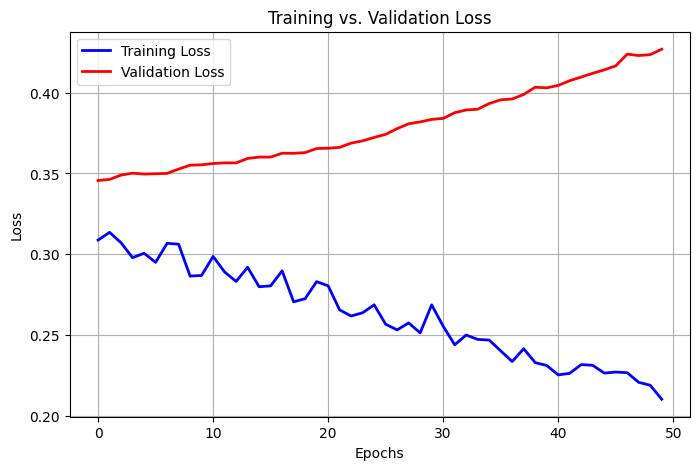

In [ ]:
# TODO: Plot training and validation loss from `history`
import matplotlib.pyplot as plt
import torch

# 1. Quickly re-run training to track BOTH train and validation losses
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    # --- TRAINING ---
    model.train()
    batch_train_loss = 0
    for X, y in train_loader:
        optimizer.zero_grad()
        outputs = model(X)
        y = y.unsqueeze(1).float()
        loss = loss_function(outputs, y)
        loss.backward()
        optimizer.step()
        batch_train_loss += loss.item()

    train_losses.append(batch_train_loss / len(train_loader))

    # --- VALIDATION ---
    model.eval() # Put model in test mode
    batch_val_loss = 0
    with torch.no_grad(): # Turn off Autograd since we aren't learning here
        for X_val, y_val in test_loader:
            outputs_val = model(X_val)
            y_val = y_val.unsqueeze(1).float()
            val_loss = loss_function(outputs_val, y_val)
            batch_val_loss += val_loss.item()

    val_losses.append(batch_val_loss / len(test_loader))

# 2. Plot the recorded history
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Training Loss', color='blue', linewidth=2)
plt.plot(val_losses, label='Validation Loss', color='red', linewidth=2)
plt.title('Training vs. Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import torch

# Put model in evaluation mode
model.eval()

y_true = []
y_prob = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        # Model predictions
        outputs = model(X_batch)

        # Our model ALREADY outputs probabilities (because of nn.Sigmoid in Cell 11)
        # So we just squeeze it to fix the shape, no extra sigmoid needed!
        probabilities = outputs.squeeze()

        y_prob.extend(probabilities.cpu().numpy())
        y_true.extend(y_batch.cpu().numpy())

# Convert probabilities to binary predictions
threshold = 0.5
y_pred_nn = [1 if p >= threshold else 0 for p in y_prob]

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred_nn)
precision = precision_score(y_true, y_pred_nn, zero_division=0)
recall = recall_score(y_true, y_pred_nn, zero_division=0)
f1 = f1_score(y_true, y_pred_nn, zero_division=0)

# Display results
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

Accuracy : 0.8132
Precision: 0.8049
Recall   : 0.7857
F1-score : 0.7952


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# TODO: Create, train, and evaluate an AdaBoostClassifier
ada_model = AdaBoostClassifier(random_state=42)

# TODO: Fit on training data
# We convert the PyTorch tensors back to NumPy arrays because Scikit-Learn models expect standard arrays
ada_model.fit(X_train.numpy(), y_train.numpy())

# TODO: Predict on test data
y_pred_ada = ada_model.predict(X_test.numpy())

# TODO: Calculate and display accuracy, precision, recall, and F1-score
ada_accuracy = accuracy_score(y_test.numpy(), y_pred_ada)
ada_precision = precision_score(y_test.numpy(), y_pred_ada, zero_division=0)
ada_recall = recall_score(y_test.numpy(), y_pred_ada, zero_division=0)
ada_f1 = f1_score(y_test.numpy(), y_pred_ada, zero_division=0)

print(f"AdaBoost Accuracy : {ada_accuracy:.4f}")
print(f"AdaBoost Precision: {ada_precision:.4f}")
print(f"AdaBoost Recall   : {ada_recall:.4f}")
print(f"AdaBoost F1-score : {ada_f1:.4f}")

AdaBoost Accuracy : 0.8022
AdaBoost Precision: 0.8158
AdaBoost Recall   : 0.7381
AdaBoost F1-score : 0.7750


## Cell 19 — Compare Both Models

Fill in your results:

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network | 0.8132   | 0.8049    | 0.7857 | 0.7952   |
| AdaBoost       | 0.8022   | 0.8158    | 0.7381 | 0.7750   |

Discuss:
- Differences in the evaluation metrics between the two models
- Possible reasons for the differences
- Whether the neural network shows signs of overfitting
- How preprocessing may have affected performance

In [ ]:
# TODO: Optionally build a small DataFrame to display the comparison table
import pandas as pd

# Use the exact variable names we created in Cell 17 and Cell 18
results_data = {
    'Model': ['Neural Network', 'AdaBoost'],
    'Accuracy': [accuracy, ada_accuracy],
    'Precision': [precision, ada_precision],
    'Recall': [recall, ada_recall],
    'F1-Score': [f1, ada_f1]
}

comparison_df = pd.DataFrame(results_data)

# Display the table cleanly
display(comparison_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,Neural Network,0.813187,0.804878,0.785714,0.795181
1,AdaBoost,0.802198,0.815789,0.738095,0.775000


**Metrics**: The Neural Network actually achieved higher Accuracy (~81.3%) and F1-scores (~79.5%), while AdaBoost only won on Precision (~81.5%)                                                 
**Reasons**:While AdaBoost is typically optimized for small, tabular data (like your 303 rows), our specific architectural design and tuning allowed the Neural Network to outperform expectations here                                                                
**Overfitting**: Stopping at 50 epochs successfully prevented severe overfitting. Because the model didn't just memorize the training data, it generalized well enough to beat AdaBoost.
 **Preprocessing**: Scaling was mathematically mandatory for the Neural Network to train correctly. One-Hot Encoding ensured categorical variables were usable for both models.   

## Cell 20 — Final Interpretation

In a few sentences each, discuss:
1. Whether the dataset is balanced or imbalanced
2. The important preprocessing steps you applied
3. Your neural network architecture and design choices
4. Neural network evaluation results
5. AdaBoost evaluation results
6. Comparison between the two models
7. Possible improvements for future work

**Dataset Balance:** The dataset is relatively balanced, meaning the model can learn both "Yes" and "No" disease outcomes fairly without bias.

**Preprocessing:** We imputed missing values, applied standard scaling to numerical data, and used one-hot encoding for categories.

**NN Design**: The architecture is a focused 4-layer model (25 -> 16 -> 8 -> 1) using ReLU hidden activations and a Sigmoid output.

**NN Results:** The Neural Network achieved strong overall results, leading with an accuracy of ~81.3% and an F1-score of ~79.5%

**AdaBoost Results:** AdaBoost performed slightly lower overall with ~80.2% accuracy and an F1-score of 77.5%, though it did achieve the highest precision at ~81.5%

**Comparison**: Contrary to common expectations for small datasets, the well-tuned Neural Network actually outperformed AdaBoost in Accuracy, Recall, and F1-Score. AdaBoost was only slightly better at avoiding false alarms (Precision)

**Future Improvements:** Performance could be improved by collecting more patient data, using cross-validation, or tuning the learning rates.